# Planning Stages

In [43]:
import matplotlib.pyplot as plt
from pathlib import Path
import mat73
import numpy as np
from scipy.signal import find_peaks

## Plan 

#### CNN
Build a PPG 1D CNN to produce a 32-dimensional embedding and SBP/DBP predictions
- maybe find a pretrained CNN from hugging face??
- MOMENT-1 (general time-series transformer)

#### ECG + PPG Calculation 
Using both ecg + ppg data, calculate PAT (pulse arrival time) and HRV and add to data as a sort of preprocessing method




In [7]:
# ECG+PPG calculation

data_dir = Path("/Users/sand/Downloads/OneDrive_5_11-8-2026")
files = sorted(data_dir.glob("*.mat"))

print("Files found:", len(files))
print([file.name for file in files[:5]])

Files found: 6
['p000047.mat', 'p000050.mat', 'p000056.mat', 'p000058.mat', 'p000059.mat']


In [32]:
# Find keys

data = mat73.loadmat(str(files[1])) # change number for diff. patient

data.keys()
type(data["Subj_Wins"])
data["Subj_Wins"].keys()

dict_keys(['ABP_F', 'ABP_Lag', 'ABP_Raw', 'ABP_SPeaks', 'ABP_Turns', 'Age', 'BMI', 'CaseID', 'ECG_F', 'ECG_RPeaks', 'ECG_Raw', 'ECG_Record', 'ECG_Record_F', 'Gender', 'Height', 'IncludeFlag', 'PPG_ABP_Corr', 'PPG_F', 'PPG_Raw', 'PPG_Record', 'PPG_Record_F', 'PPG_SPeaks', 'PPG_Turns', 'SegDBP', 'SegSBP', 'SegmentID', 'SubjectID', 'T', 'Weight', 'WinID', 'WinSeqID'])

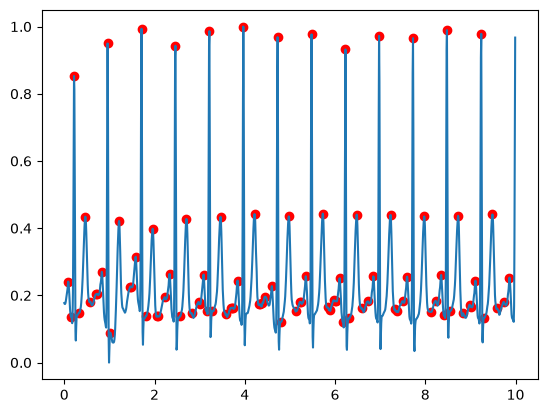

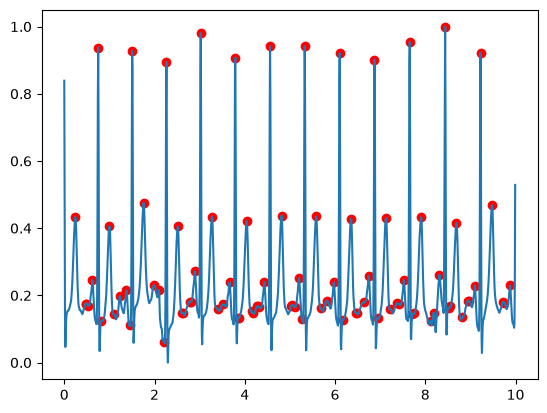

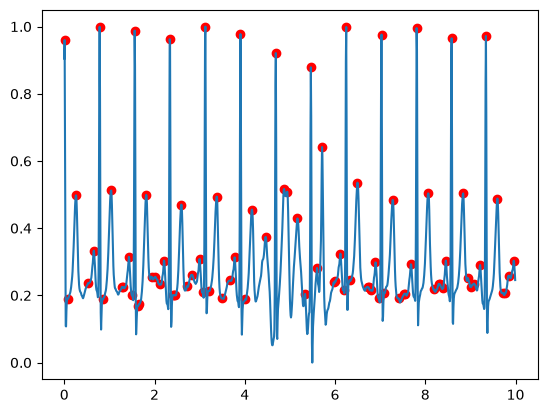

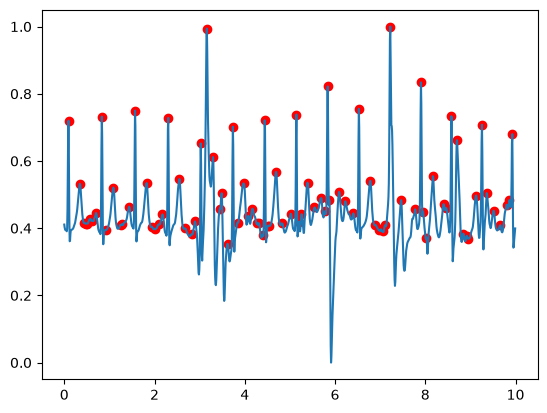

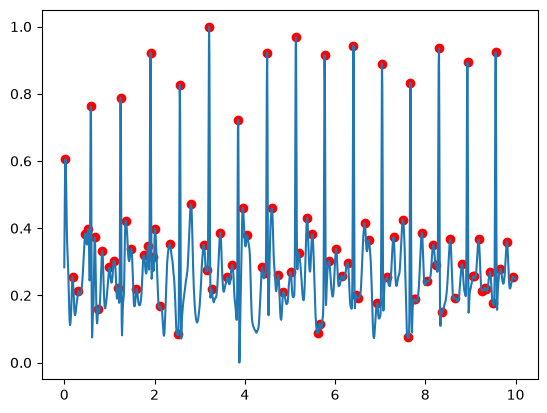

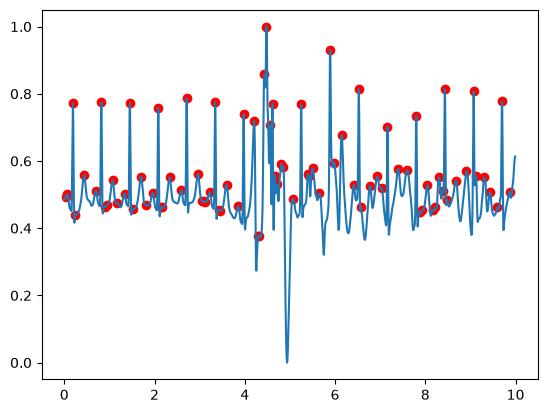

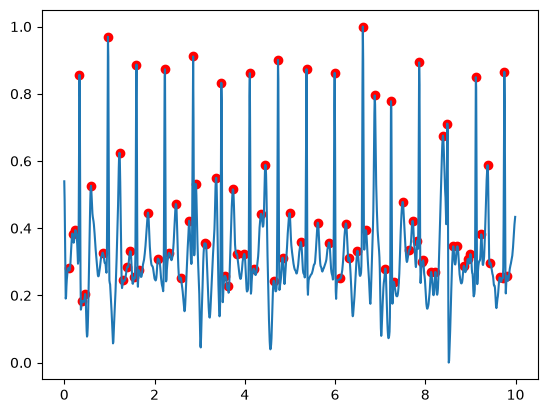

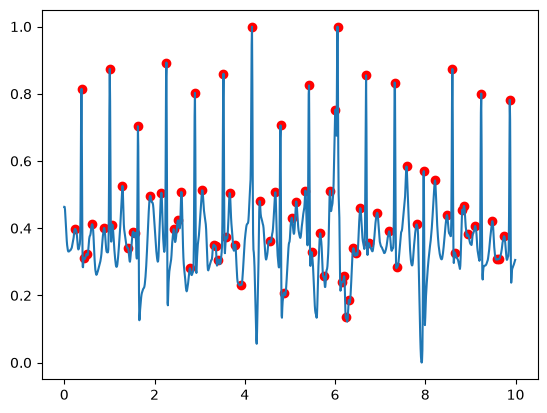

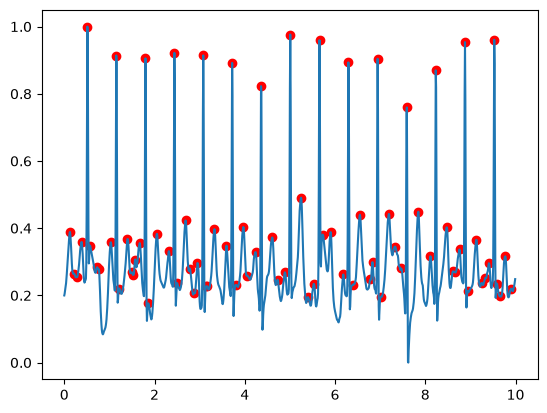

In [33]:
windows = data["Subj_Wins"]

t = windows["T"][0][0] # assume that t is same across data
relative_time = t - t[0]
mask = relative_time < 4
min_distance = int(0.3 * 125)

# ecg plots
for i in range(9):
    ecg_i = windows["ECG_F"][i][0]

    peaks_ecg_i, properties_ecg_i = find_peaks(ecg_i)#, distance=min_distance) #, 0.64))
    
    fig, ax = plt.subplots()
    plt.plot(relative_time, ecg_i)
    plt.scatter(relative_time[peaks_ecg_i], ecg_i[peaks_ecg_i], color="red")
    #plt.xlim(2,3)

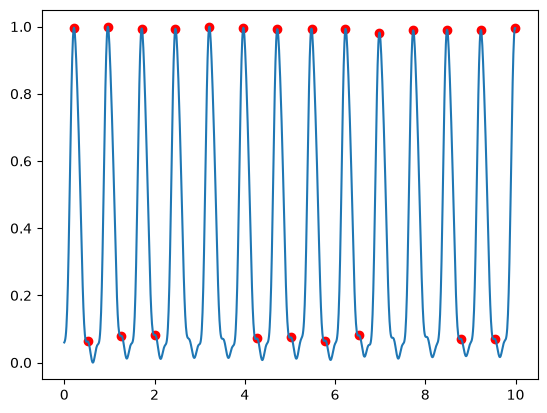

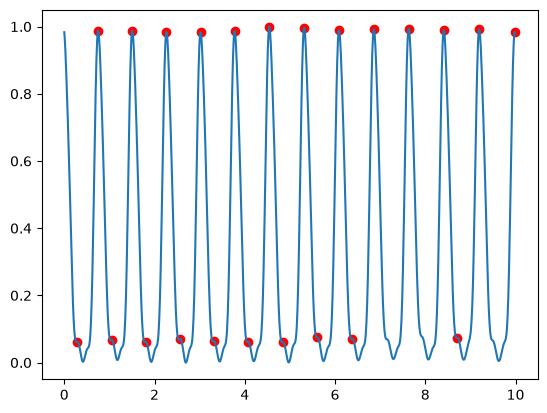

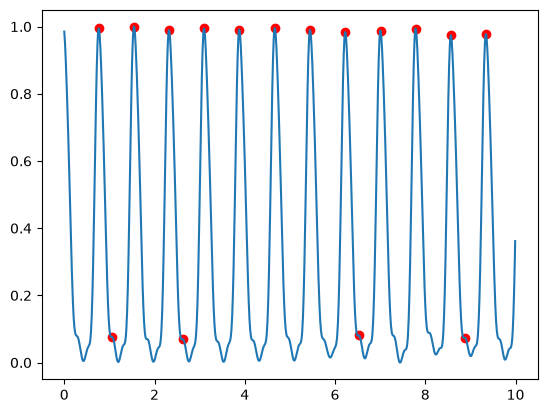

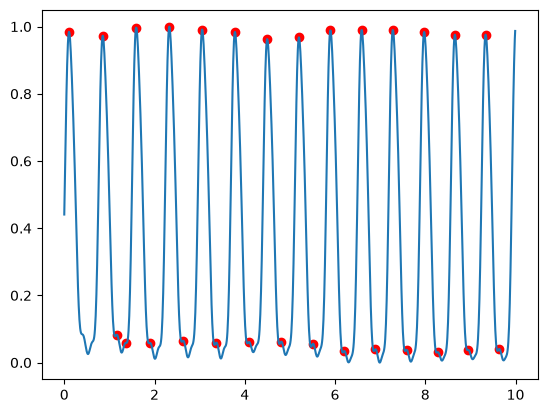

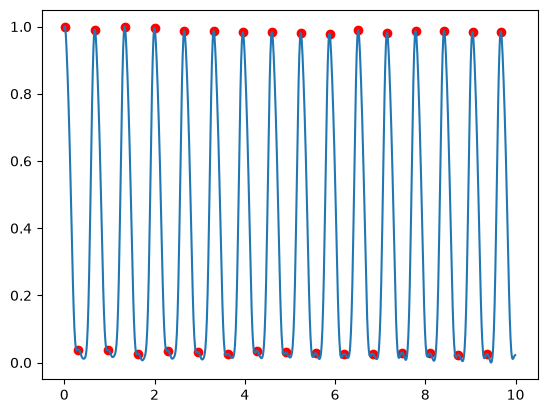

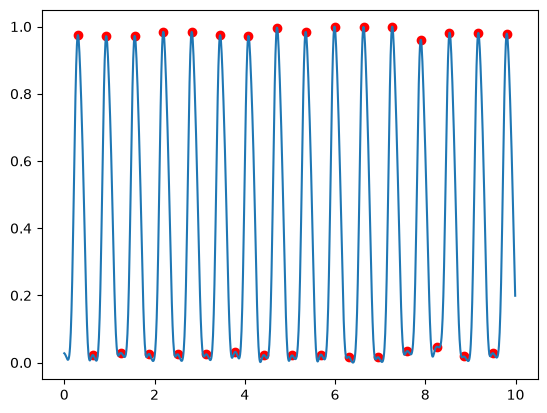

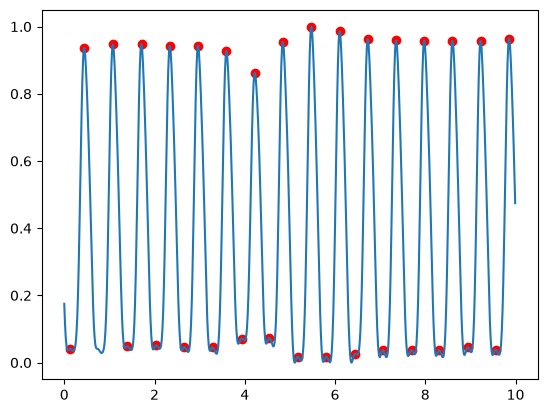

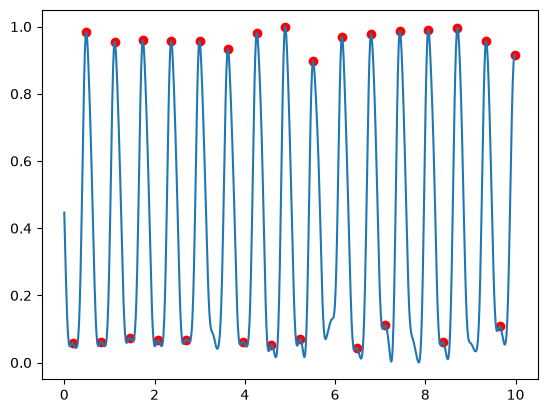

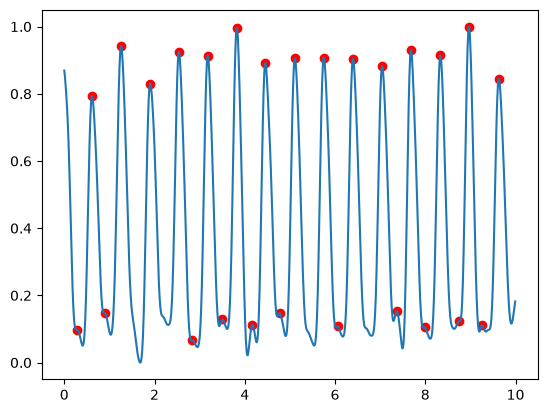

In [53]:
# ppg plots
for i in range(9):
    ppg_i = windows["PPG_F"][i][0]

    peaks_ppg_i, properties_ppg_i = find_peaks(ppg_i)#, distance=min_distance) #, 0.64))
    
    fig, ax = plt.subplots()
    plt.plot(relative_time, ppg_i)
    plt.scatter(relative_time[peaks_ppg_i], ppg_i[peaks_ppg_i], color="red")
    #plt.xlim(2,3)

In [61]:
# function 
'''
preprocessing function that retrieves ecg and ppg data and performs
rr interval calculations.

input: 
- data: patient file
- idx: window index
- fs = freq. (set to 125)
'''
def extract_features(data, idx, fs=125): 
    windows = data["Subj_Wins"]

    # data retrival
    ecg = windows["ECG_F"][idx][0]
    ppg = windows["PPG_F"][idx][0]
    ecg_rpeaks = windows["ECG_RPeaks"][idx][0]
    ppg_speaks = windows["PPG_SPeaks"][idx][0]

    rr_s = np.diff(ecg_rpeaks) / fs # calc. r-peak to r-peak
    mean_rr_s = np.mean(rr_s) if len(rr_s) >= 1 else np.nan
    
    rmssd_ms = (
        np.sqrt(np.mean(np.diff(rr_s) ** 2)) * 1000
        if len(rr_s) >= 2 else np.nan
    )

    rr_std_ms = (
        np.std(rr_s, ddof=1) * 1000
        if len(rr_s) >= 2 else np.nan
    )
    
    return {
        "window_index": idx,
        "n_r_peaks": len(ecg_rpeaks),
        "n_s_peaks": len(ppg_speaks),
        "rr_s": rr_s,
        "mean_rr_s": mean_rr_s,
        "rr_std_ms": rr_std_ms,
        "rmssd_ms": rmssd_ms,
    }
    

ok lets go

In [62]:
# test
features = extract_features(data, 0)
print(features)

{'window_index': 0, 'n_r_peaks': 5, 'n_s_peaks': 14, 'rr_s': array([0.752, 0.752, 0.76 , 0.752]), 'mean_rr_s': np.float64(0.754), 'rr_std_ms': np.float64(4.0000000000000036), 'rmssd_ms': np.float64(6.5319726474218145)}


| Field | Your value | Meaning |
|---|---|---|
| `window_index` | `0` | The first window in the loaded file. |
| `n_r_peaks` | `5` | Five annotated ECG R-peaks, giving four RR intervals. |
| `rr_s` | `[0.752, 0.752, 0.760, 0.752]` | Time in seconds between consecutive R-peaks. |
| `mean_rr_s` | `0.754` | Average RR interval: 754 ms, corresponding to approximately 79.6 beats/minute. |
| `rr_std_ms` | `4.0` | Sample standard deviation of the RR intervals, in milliseconds. |
| `rmssd_ms` | `6.53` | Root mean square of successive RR-interval differences, in milliseconds. |

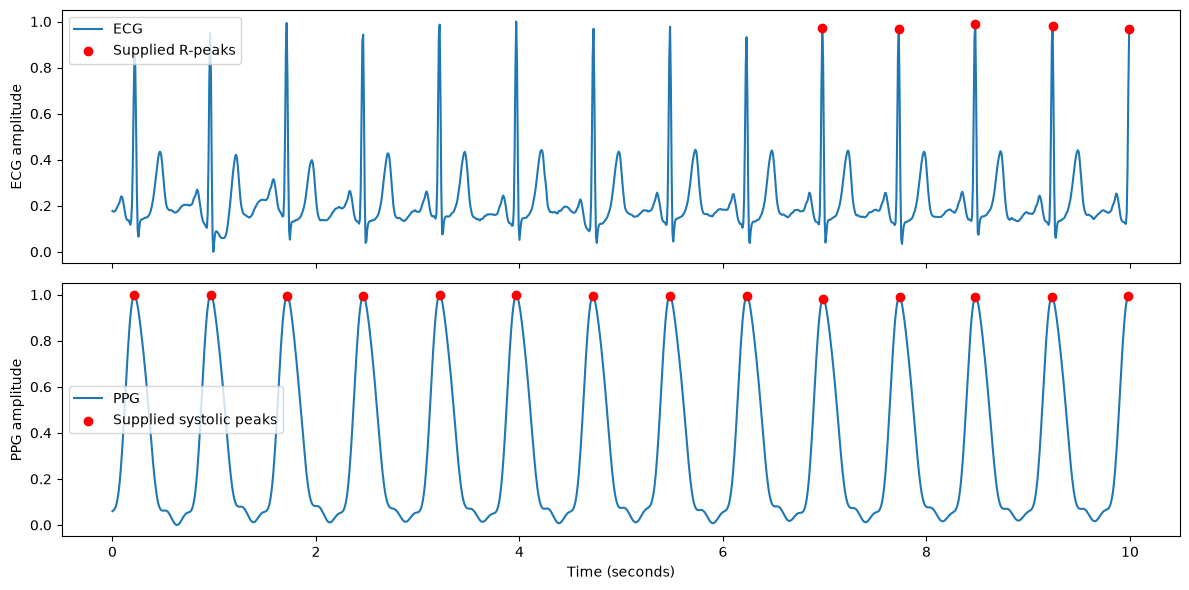

In [64]:
'''
issue with window 0 
- r peaks are not correctly identifed; 
- 
'''
i = 0
fs = 125
windows = data["Subj_Wins"]

ecg = windows["ECG_F"][i][0]
ppg = windows["PPG_F"][i][0]

# Assuming MATLAB's 1-based sample indices
r_idx = windows["ECG_RPeaks"][i][0].astype(int) - 1
p_idx = windows["PPG_SPeaks"][i][0].astype(int) - 1

t = np.arange(len(ecg)) / fs

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(t, ecg, label="ECG")
axes[0].scatter(t[r_idx], ecg[r_idx], color="red",
                label="Supplied R-peaks", zorder=3)
axes[0].set_ylabel("ECG amplitude")
axes[0].legend()

axes[1].plot(t, ppg, label="PPG")
axes[1].scatter(t[p_idx], ppg[p_idx], color="red",
                label="Supplied systolic peaks", zorder=3)
axes[1].set_ylabel("PPG amplitude")
axes[1].set_xlabel("Time (seconds)")
axes[1].legend()

plt.tight_layout()
plt.show()